# 09 Feature redundancy and tree model importances

Exploratory analysis subsequent to the main results. Paired LOSO comparison between the full pipeline and the redundancy-reduced pipeline. Feature selection is re-performed within the training of each inner fold and outer training set: no test subjects enter selection or tuning.

Internal importances of tree models and test permutation importances are descriptive, not causal. Do not use test importances to select features and then declare the resulting performance as independent.

## Execution and recovery
Run setup, function definitions, and the full training cell before plotting. 
Tables are checkpointed after each completed fold. The plotting cell reads saved tables 
and rejects missing tree importances instead of silently skipping them. 
Saved metrics alone cannot recover importance values when fitted models were not saved. 
The training cell starts a new run and overwrites its checkpoint files; it does not automatically resume. 
All three thresholds (0.95, 0.90, 0.80) are post-hoc sensitivity analyses.


In [1]:
from pathlib import Path
import sys, os, json, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import display, Image, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.inspection import permutation_importance

PROJECT_ROOT = None
here=Path.cwd().resolve()
ROOT=Path(PROJECT_ROOT).resolve() if PROJECT_ROOT else next(
    (p for p in [here,*here.parents] if (p/'configs/config.yaml').is_file() and (p/'src').is_dir()),None)
if ROOT is None: raise RuntimeError('Salva il notebook in notebooks/ oppure imposta PROJECT_ROOT.')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src import workflow as w
from src.config import load, fingerprint
from src.models import pipeline as original_pipeline, grid, feature_columns
from src.splits import loso, inner
from src.fusion import comparison_tables

c=load()
lock=json.loads((w.root(c)/'protocol_lock.json').read_text(encoding='utf-8'))
c=copy.deepcopy(lock['config'])
if fingerprint(c)!=lock['config_sha256']: raise ValueError('Protocollo non coerente.')
OUT=w.root(c)/'exploratory/feature_redundancy_importance'
OUT.mkdir(parents=True,exist_ok=True)

# Soglia fissata, NON ottimizzata sul test. Cambiarla crea un'altra analisi esplorativa.
CORRELATION_THRESHOLDS=[0.95,0.90,0.80]
CORRELATION_METHOD='spearman'
SITES=['early_fusion','chest','wrist']
MODELS=['logistic_regression','random_forest']
# Per includere i boosting, se installati:
# MODELS += ['xgboost','lightgbm']
N_PERMUTATION_REPEATS=10
TOP_N=20
SAVE_MODELS=False
SEED=c['splits']['seed']
tables=w.load_tables(c)
frames=comparison_tables(tables,paired_only=True)
def show(fig,name):
    fig.savefig(OUT/name,dpi=160,bbox_inches='tight')
    with BytesIO() as b:
        fig.savefig(b,format='png',dpi=125,bbox_inches='tight'); data=b.getvalue()
    plt.close(fig);display(Image(data=data))
print('Analysis output directory ready.')
print('Il notebook riaddestra modelli con tuning annidato: può richiedere tempo.')


Analysis output directory ready.
Il notebook riaddestra modelli con tuning annidato: può richiedere tempo.


## Selettore della ridondanza

Spearman assoluto tra feature nel solo training. Ordine alfabetico deterministico, indipendente dalle etichette: si mantiene la prima feature disponibile e si scartano quelle troppo correlate con una feature già mantenuta. Non garantisce di trovare il sottoinsieme migliore. Si registrano tutte le esclusioni. Feature costanti o interamente mancanti sono rimosse nella variante ridotta.

La correlazione pooled può riflettere differenze tra soggetti o condizioni: non è un test di associazione fisiologica entro persona. La soglia è una regola ingegneristica e non risolve tutte le forme di multicollinearità.

In [2]:
class CorrelationSelector(TransformerMixin, BaseEstimator):
    def __init__(self, threshold=0.90, method='spearman'):
        self.threshold=threshold; self.method=method
    def fit(self,X,y=None):
        if not isinstance(X,pd.DataFrame): raise TypeError('Servono DataFrame con nomi.')
        if not 0 < self.threshold <= 1: raise ValueError('Soglia non valida.')
        X=X.replace([np.inf,-np.inf],np.nan)
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.n_features_in_=len(X.columns)
        columns=sorted(X.columns)
        usable=[col for col in columns if X[col].nunique(dropna=True)>1]
        self.correlation_=X[usable].corr(method=self.method,min_periods=3).abs()
        self.kept_=[];self.removed_=[]
        for col in columns:
            if col not in usable:
                self.removed_.append(dict(feature=col,reason='constant_or_all_missing',representative=None,abs_r=np.nan))
                continue
            matches=[other for other in self.kept_ if self.correlation_.loc[col,other]>=self.threshold]
            if matches:
                other=matches[0]
                self.removed_.append(dict(feature=col,reason='correlated',representative=other,
                                          abs_r=float(self.correlation_.loc[col,other])))
            else:self.kept_.append(col)
        if not self.kept_:raise ValueError('Nessuna feature rimasta.')
        return self
    def transform(self,X):return X.loc[:,self.kept_].copy()
    def get_feature_names_out(self,input_features=None):return np.asarray(self.kept_,dtype=object)

def make_pipeline(model_name,reduced):
    base=original_pipeline(model_name,c)
    steps=list(base.steps)
    if reduced is not None:steps=[('correlation',CorrelationSelector(reduced,CORRELATION_METHOD))]+steps
    return Pipeline(steps)

def tune_training(train,cols,model_name,reduced):
    base=make_pipeline(model_name,reduced)
    best_params=None;best_score=-np.inf;trace=[]
    for params in ParameterGrid(grid(model_name,c)):
        scores=[]
        for tr,va in inner(train,c['splits']['inner_folds']):
            fit=clone(base).set_params(**params)
            fit.fit(train.iloc[tr][cols],train.iloc[tr]['label'])
            valid=train.iloc[va]
            guessed=fit.predict(valid[cols])
            for sid in valid.subject_id.unique():
                mask=valid.subject_id.to_numpy()==sid
                if set(valid.loc[mask,'label'])!={1,2,3}:raise ValueError('Classe assente in validazione.')
                scores.append(balanced_accuracy_score(valid.loc[mask,'label'],guessed[mask]))
        score=float(np.mean(scores));trace.append({'params':params,'score':score})
        if score>best_score:best_score=score;best_params=params
    fitted=clone(base).set_params(**best_params).fit(train[cols],train['label'])
    return fitted,{'best_params':best_params,'inner_score':best_score,'trace':trace}


## Training and importances

The comparison uses the same subjects and windows across both variants. Internal RF importances are impurity-based; for LightGBM and XGBoost, the native model-declared type is retained. They are normalized per fold and are not directly comparable as absolute units across algorithms.

Permutation importance measures the drop in balanced accuracy on the test subject when a feature is permuted. Correlation can mask individual feature importance. Permuting windows disrupts temporal structure: this is a diagnostic perturbation, not a temporal significance test. The deviation across repetitions is not a confidence interval across individuals.

In [3]:
fold_rows=[];prediction_rows=[];selection_rows=[];importance_rows=[];warning_rows=[];traces=[]
for site in SITES:
    frame=frames[site].reset_index(drop=True)
    cols=feature_columns(frame)
    if np.isinf(frame[cols].to_numpy(float)).any():raise ValueError('Feature infinite: controllare estrazione.')
    for model_name in MODELS:
        for variant in ['full','reduced_0.95','reduced_0.90','reduced_0.80']:
            for tr,te in loso(frame,(1,2,3)):
                train,test=frame.iloc[tr],frame.iloc[te]
                sid=int(test.subject_id.iloc[0])
                print(f'{site} | {model_name} | {variant} | S{sid}',flush=True)
                with warnings.catch_warnings(record=True) as observed:
                    warnings.simplefilter('always')
                    fitted,trace=tune_training(train,cols,model_name,float(variant.split('_')[1]) if variant.startswith('reduced_') else None)
                    predicted=fitted.predict(test[cols])
                    probabilities=fitted.predict_proba(test[cols])
                    kept=(fitted.named_steps['correlation'].kept_ if variant.startswith('reduced_') else cols)
                    common=dict(site=site,model=model_name,variant=variant,subject_id=sid)
                    fold_rows.append({**common,'n_windows':len(test),'n_features':len(kept),
                        'balanced_accuracy':balanced_accuracy_score(test.label,predicted),
                        'f1_macro':f1_score(test.label,predicted,labels=[1,2,3],average='macro',zero_division=0),
                        **{f'recall_{k}':float(np.mean(predicted[test.label.to_numpy()==k]==k)) for k in [1,2,3]}})
                    traces.append({**common,**trace})
                    for col in cols:selection_rows.append({**common,'feature':col,'selected':col in kept})
                    if variant.startswith('reduced_'):
                        pd.DataFrame(fitted.named_steps['correlation'].removed_).to_csv(
                            OUT/f'removed_{site}_{model_name}_{variant}_S{sid}.csv',index=False)
                    for j,row in enumerate(test.itertuples()):
                        prediction_rows.append({**common,'window_id':row.window_id,'label':int(row.label),
                            'prediction':int(predicted[j]),**{f'p_{int(k)}':float(probabilities[j,i]) for i,k in enumerate(fitted.classes_)}})
                    estimator=fitted.named_steps['model']
                    # Only the project's label-encoding wrapper should be unwrapped.
                    # RF.estimator_ is an unfitted base-tree template, not the forest.
                    tree=(estimator.estimator_ if hasattr(estimator,'encoder_')
                          and hasattr(estimator,'estimator_') else estimator)
                    if model_name in ['random_forest','xgboost','lightgbm'] and not hasattr(tree,'feature_importances_'):
                        raise RuntimeError(f'Expected tree feature importances missing: {model_name}, {type(tree).__name__}')
                    if hasattr(tree,'feature_importances_'):
                        # Recover names after preprocessing, not merely before imputation.
                        feature_names=fitted[:-1].get_feature_names_out()
                        values=np.asarray(tree.feature_importances_,float)
                        if len(values)!=len(feature_names):raise ValueError('Nomi e importanze non allineati.')
                        total=values.sum()
                        importance_type=('impurity' if model_name=='random_forest' else str(getattr(tree,'importance_type','library_default')))
                        for feature,value in zip(feature_names,values):
                            importance_rows.append({**common,'kind':'internal_normalized','importance_type':importance_type,
                                'feature':feature,'importance':float(value/total) if total else 0.,'repeat_std':np.nan})
                        pi=permutation_importance(fitted,test[cols],test.label,
                            scoring='balanced_accuracy',n_repeats=N_PERMUTATION_REPEATS,
                            random_state=SEED+sid,n_jobs=1)
                        for feature,value,std in zip(cols,pi.importances_mean,pi.importances_std):
                            importance_rows.append({**common,'kind':'permutation_test','importance_type':'BA_drop',
                                'feature':feature,'importance':float(value),'repeat_std':float(std)})
                    for warning in observed:
                        warning_rows.append({**common,'category':warning.category.__name__,'message':str(warning.message)})
                if SAVE_MODELS:
                    import joblib
                    joblib.dump(fitted,OUT/f'{site}_{model_name}_{variant}_S{sid}.joblib')
                # Incremental outputs preserve completed folds if execution is interrupted.
                fold_metrics=pd.DataFrame(fold_rows)
                selection=pd.DataFrame(selection_rows)
                importances=pd.DataFrame(importance_rows,columns=[
                    'site','model','variant','subject_id','kind','importance_type',
                    'feature','importance','repeat_std'])
                fold_metrics.to_csv(OUT/'fold_metrics.csv',index=False)
                selection.to_csv(OUT/'feature_selection.csv',index=False)
                importances.to_csv(OUT/'feature_importances.csv',index=False)
                pd.DataFrame(prediction_rows).to_csv(OUT/'predictions.csv',index=False)
                pd.DataFrame(warning_rows).to_csv(OUT/'fit_warnings.csv',index=False)
                print(f'Completed fold; collected importance rows: {len(importances)}',flush=True)
fold_metrics=pd.DataFrame(fold_rows)
selection=pd.DataFrame(selection_rows)
importances=pd.DataFrame(importance_rows)
pd.DataFrame(prediction_rows).to_csv(OUT/'predictions.csv',index=False)
selection.to_csv(OUT/'feature_selection.csv',index=False)
pd.DataFrame(warning_rows).to_csv(OUT/'fit_warnings.csv',index=False)
(OUT/'tuning_trace.json').write_text(json.dumps(traces,indent=2),encoding='utf-8')
print('Esecuzione completata. Warning registrati:',len(warning_rows))
estimator = fitted.named_steps['model']
tree = estimator
if model_name in ['random_forest', 'xgboost', 'lightgbm'] and not hasattr(tree, 'feature_importances_'):
    raise RuntimeError(
        f'Expected tree feature importances missing: {model_name}, {type(tree).__name__}'
    )

early_fusion | logistic_regression | full | S2
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S3
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S4
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S5
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S6
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S7
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S8
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S9
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S10
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S11
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S13
Completed fold; collected impo

## Full versus reduced paired comparison

Positive difference: reduction improves balanced accuracy. Paired bootstrap over subjects, conditional on already obtained models, without retraining during resampling. Exploratory intervals not corrected for multiple comparisons. Do not select the correlation threshold based on these results.

In [4]:
display(fold_metrics.groupby(['site','model','variant'])[['balanced_accuracy','f1_macro','recall_1','recall_2','recall_3','n_features']].agg(['mean','std']))
rng=np.random.default_rng(SEED);rows=[]
for (site,model),g in fold_metrics.groupby(['site','model']):
    pivot=g.pivot(index='subject_id',columns='variant',values='balanced_accuracy')
    for variant in ['reduced_0.95','reduced_0.90','reduced_0.80']:
        if pivot[['full',variant]].isna().any().any():raise ValueError('Fold non appaiati')
        d=(pivot[variant]-pivot['full']).to_numpy()
        boot=d[rng.integers(0,len(d),size=(10000,len(d)))].mean(1)
        low,high=np.quantile(boot,[.025,.975])
        rows.append(dict(site=site,model=model,variant=variant,delta_BA_pp=100*d.mean(),ci_low_pp=100*low,ci_high_pp=100*high))
comparison=pd.DataFrame(rows);display(comparison)
comparison.to_csv(OUT/'paired_reduced_minus_full.csv',index=False)
frequency=selection.groupby(['site','model','variant','feature']).selected.mean().rename('selection_frequency').reset_index()
frequency.to_csv(OUT/'selection_frequency.csv',index=False)
display(frequency)


balanced_accuracy            \
                                                           mean       std   
site         model               variant                                    
chest        logistic_regression full                  0.656612  0.155552   
                                 reduced_0.80          0.661878  0.177229   
                                 reduced_0.90          0.661061  0.150429   
                                 reduced_0.95          0.666880  0.159569   
             random_forest       full                  0.630460  0.158727   
                                 reduced_0.80          0.657480  0.144832   
                                 reduced_0.90          0.639795  0.129749   
                                 reduced_0.95          0.643178  0.126783   
early_fusion logistic_regression full                  0.682071  0.179244   
                                 reduced_0.80          0.661734  0.170111   
                                 reduced_0.90          0.662790  0.179288   
                                 reduced_0.95          0.690448  0.180197   
             random_forest       full                  0.674375  0.147567   
                                 reduced_0.80          0.699482  0.119024   
                                 reduced_0.90          0.723559  0.127080   
                                 reduced_0.95          0.702592  0.112288   
wrist        logistic_regression full                  0.661080  0.170277   
                                 reduced_0.80          0.648945  0.158398   
                                 reduced_0.90          0.665611  0.166426   
                                 reduced_0.95          0.658930  0.169956   
             random_forest       full                  0.682878  0.106259   
                                 reduced_0.80          0.658783  0.093995   
                                 reduced_0.90          0.683227  0.093577   
                                 reduced_0.95          0.687871  0.073017   

                                               f1_macro            recall_1  \
                                                   mean       std      mean   
site         model               variant                                      
chest        logistic_regression full          0.599212  0.171601  0.623795   
                                 reduced_0.80  0.611195  0.190637  0.662888   
                                 reduced_0.90  0.606984  0.170899  0.636155   
                                 reduced_0.95  0.609531  0.172598  0.641949   
             random_forest       full          0.594677  0.165466  0.762956   
                                 reduced_0.80  0.624667  0.154581  0.776698   
                                 reduced_0.90  0.617479  0.137512  0.797748   
                                 reduced_0.95  0.614067  0.134415  0.735482   
early_fusion logistic_regression full          0.635822  0.210268  0.715756   
                                 reduced_0.80  0.617258  0.191798  0.658363   
                                 reduced_0.90  0.621392  0.203067  0.682850   
                                 reduced_0.95  0.645215  0.207993  0.720599   
             random_forest       full          0.642351  0.182582  0.826859   
                                 reduced_0.80  0.678980  0.141213  0.858562   
                                 reduced_0.90  0.703817  0.147699  0.879771   
                                 reduced_0.95  0.683864  0.135117  0.858320   
wrist        logistic_regression full          0.634908  0.173305  0.643742   
                                 reduced_0.80  0.621459  0.159923  0.618991   
                                 reduced_0.90  0.642325  0.169039  0.629188   
                                 reduced_0.95  0.634524  0.173736  0.643742   
             random_forest       full          0.656102  0.126186  0.794852   
                                 reduced_0.80  0.636269  0.111068  0.8

,site,model,variant,delta_BA_pp,ci_low_pp,ci_high_pp
0,chest,logistic_regression,reduced_0.95,1.026739,-0.184851,2.494086
1,chest,logistic_regression,reduced_0.90,0.444907,-1.823728,2.745030
2,chest,logistic_regression,reduced_0.80,0.526587,-2.903064,5.556307
3,chest,random_forest,reduced_0.95,1.271758,-2.118663,4.777357
4,chest,random_forest,reduced_0.90,0.933448,-1.888733,3.883686
5,chest,random_forest,reduced_0.80,2.701940,-1.227977,6.397430
6,early_fusion,logistic_regression,reduced_0.95,0.837779,0.118540,1.708637
7,early_fusion,logistic_regression,reduced_0.90,-1.928037,-4.832275,0.557862
8,early_fusion,logistic_regression,reduced_0.80,-2.033652,-4.046660,-0.182047
9,early_fusion,random_forest,reduced_0.95,2.821674,-0.022889,5.565721


,site,model,variant,feature,selection_frequency
0,chest,logistic_regression,full,chest__ACC__activity_level,1.0
1,chest,logistic_regression,full,chest__ACC__movement_variance,1.0
2,chest,logistic_regression,full,chest__ACC__posture_axis_0,1.0
3,chest,logistic_regression,full,chest__ACC__posture_axis_1,1.0
4,chest,logistic_regression,full,chest__ACC__posture_axis_2,1.0
...,...,...,...,...,...
715,wrist,random_forest,reduced_0.95,wrist__EDA__std,1.0
716,wrist,random_forest,reduced_0.95,wrist__EDA__tonic_proxy,0.0
717,wrist,random_forest,reduced_0.95,wrist__TEMP__mean,1.0
718,wrist,random_forest,reduced_0.95,wrist__TEMP__slope_per_second,1.0


## Importances: subject average and stability

RF and any boosting models included in MODELS are visualized. In the reduced variant, features excluded from a fold receive an internal importance of zero solely for the purpose of the overall average; selection frequency should also be reported. Negative permutation importance means that the perturbation improved the test score, not a protective physiological effect.

site          model                variant     
chest         logistic_regression  full            15
                                   reduced_0.80    15
                                   reduced_0.90    15
                                   reduced_0.95    15
              random_forest        full            15
                                   reduced_0.80    15
                                   reduced_0.90    15
                                   reduced_0.95    15
early_fusion  logistic_regression  full            15
                                   reduced_0.80    15
                                   reduced_0.90    15
                                   reduced_0.95    15
              random_forest        full            15
                                   reduced_0.80    15
                                   reduced_0.90    15
                                   reduced_0.95    15
wrist         logistic_regression  full            15
                                  

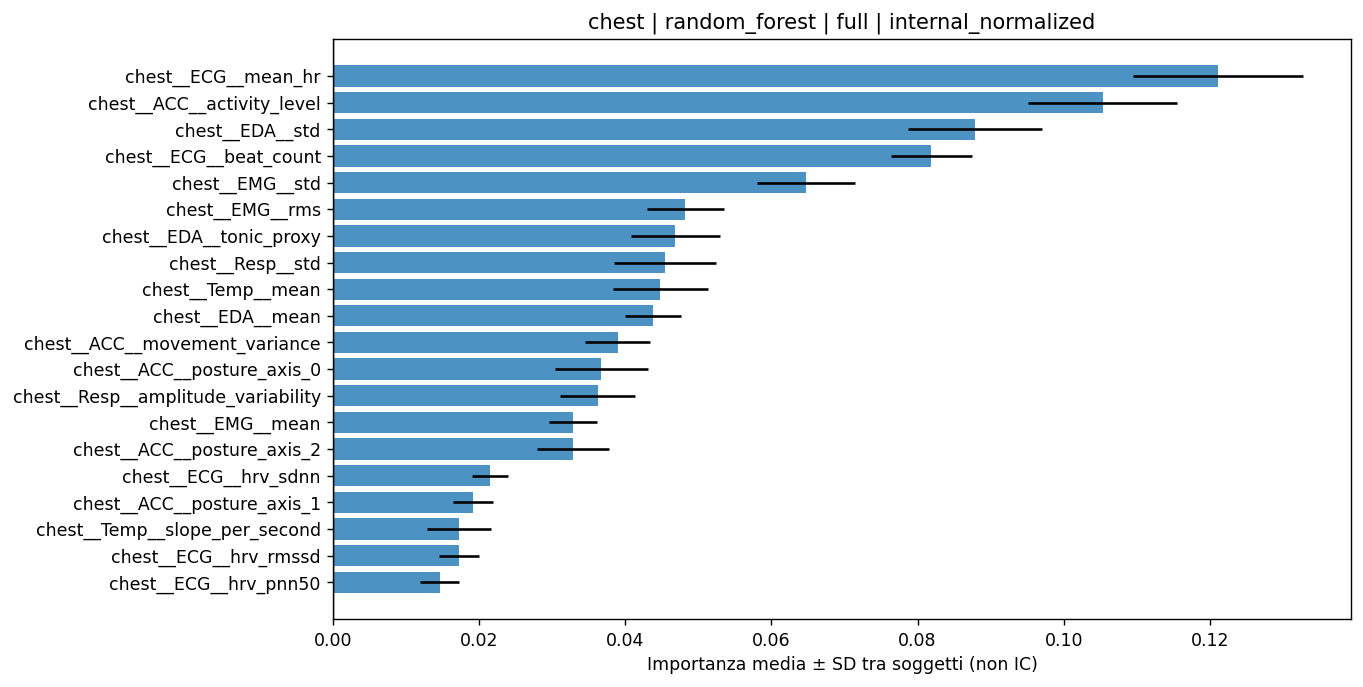

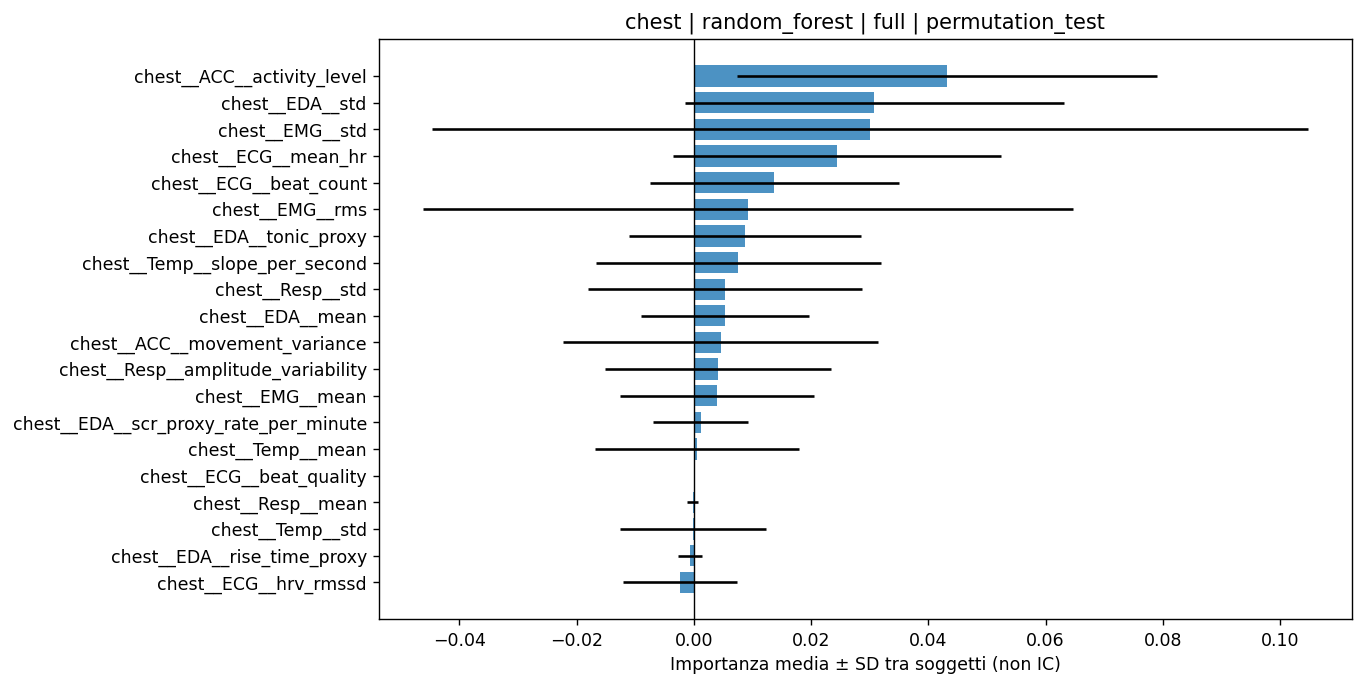

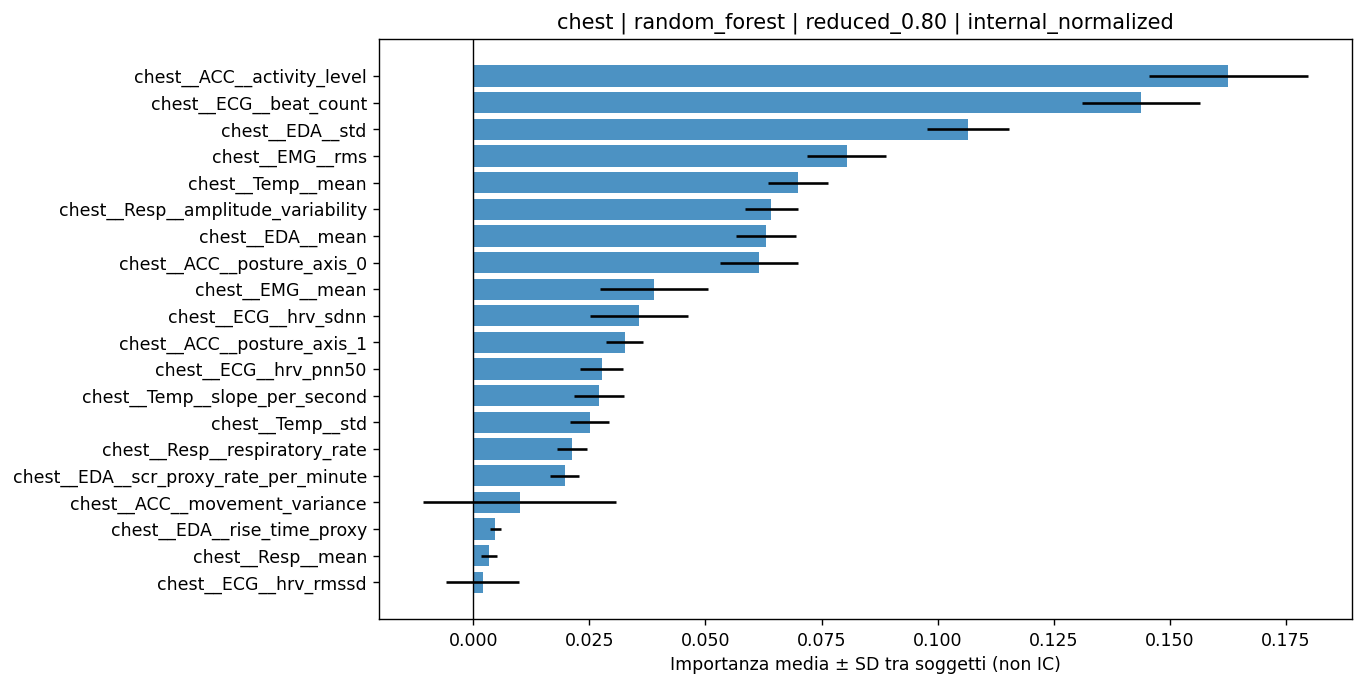

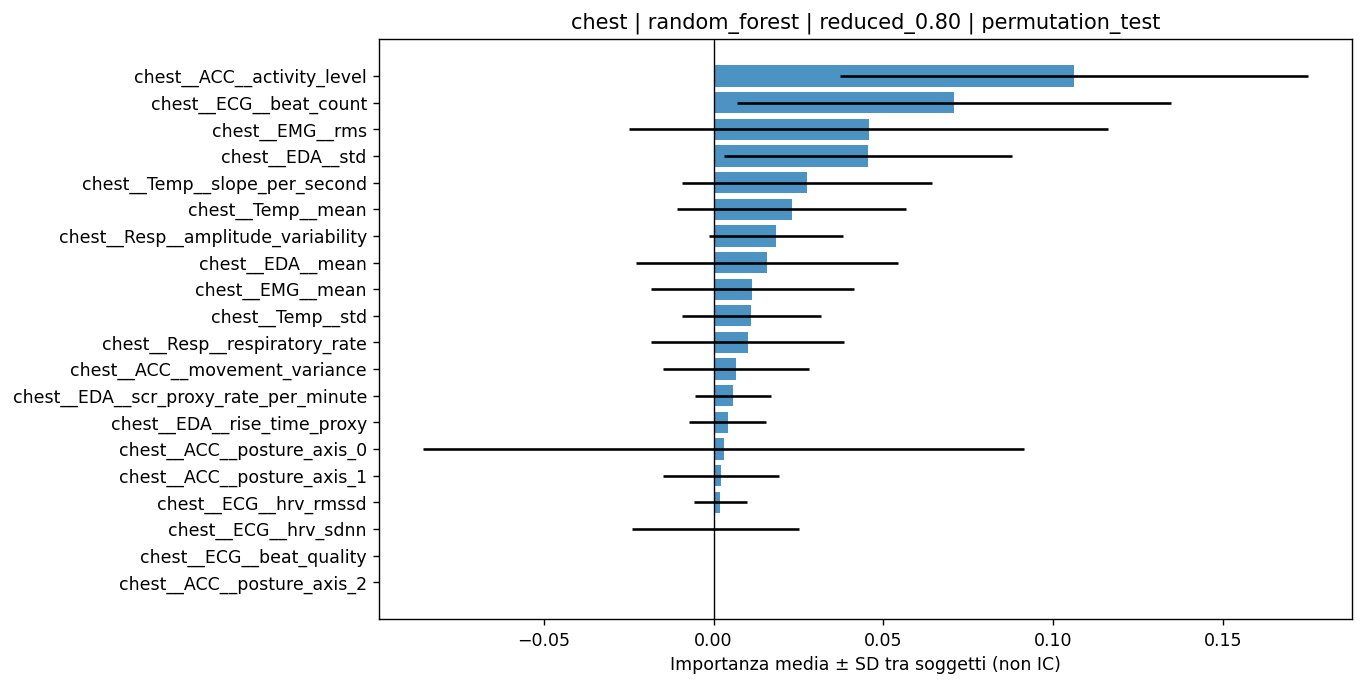

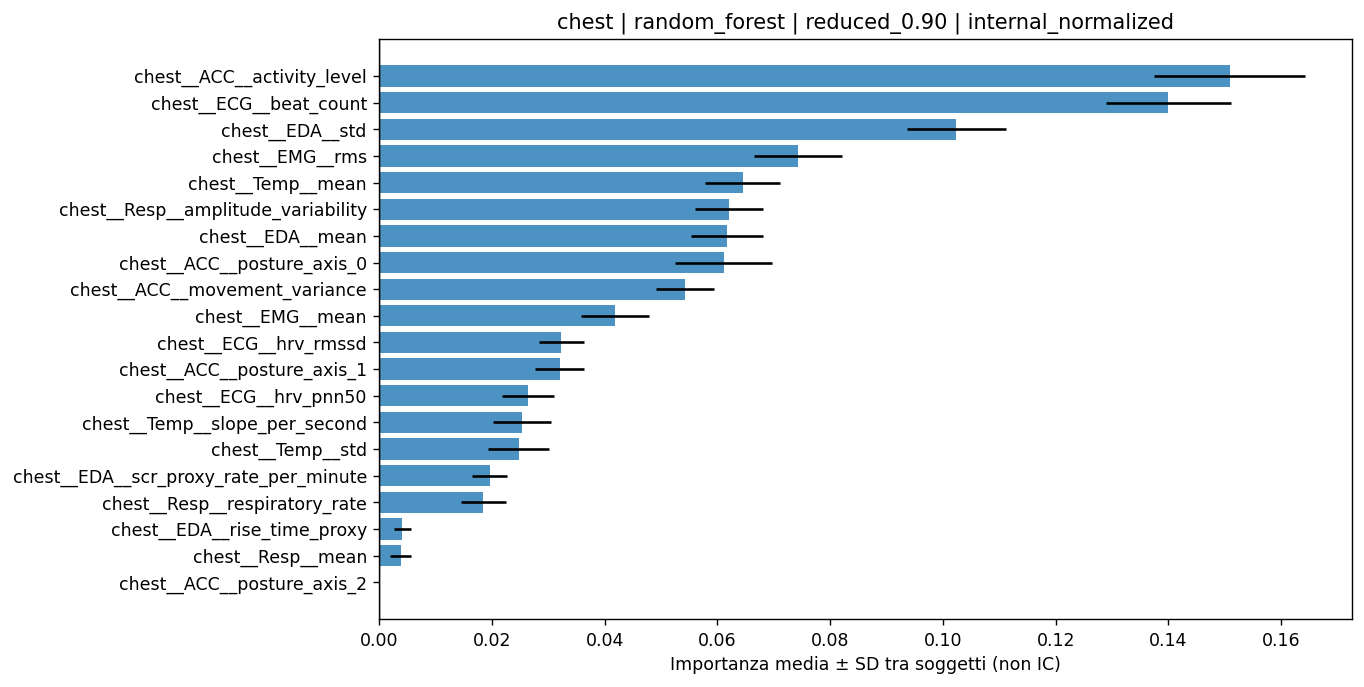

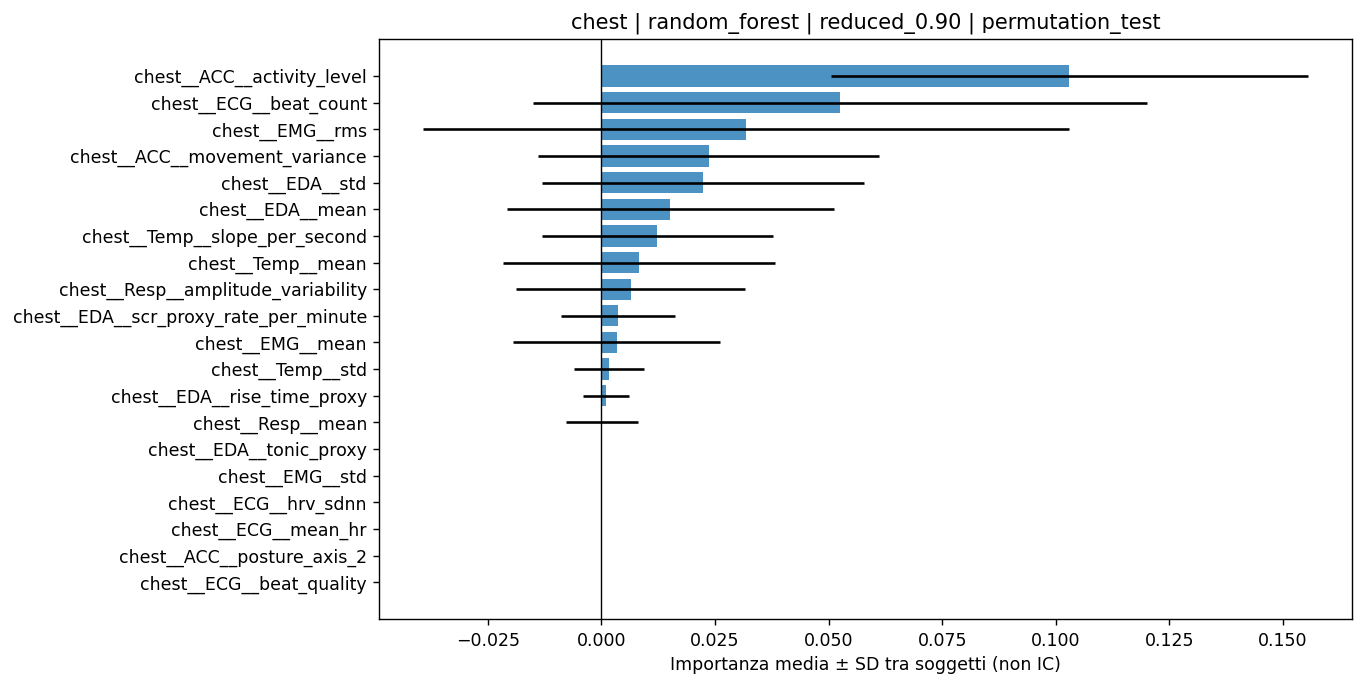

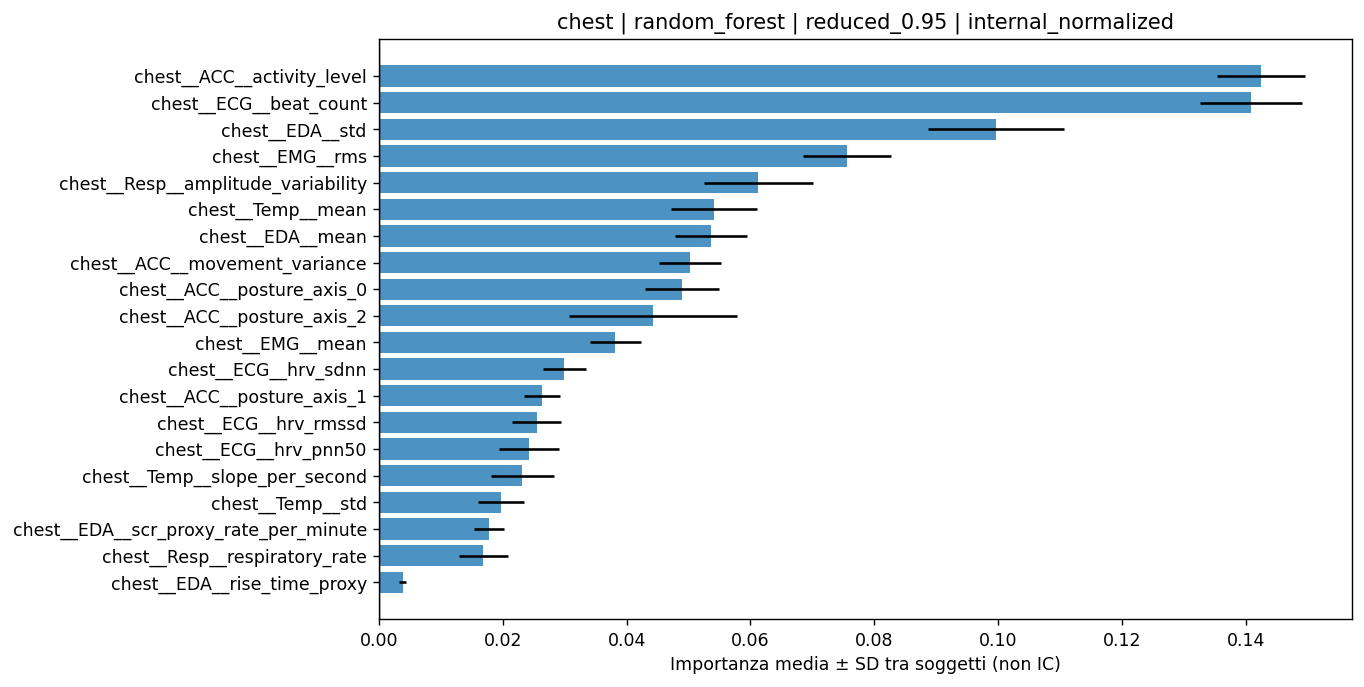

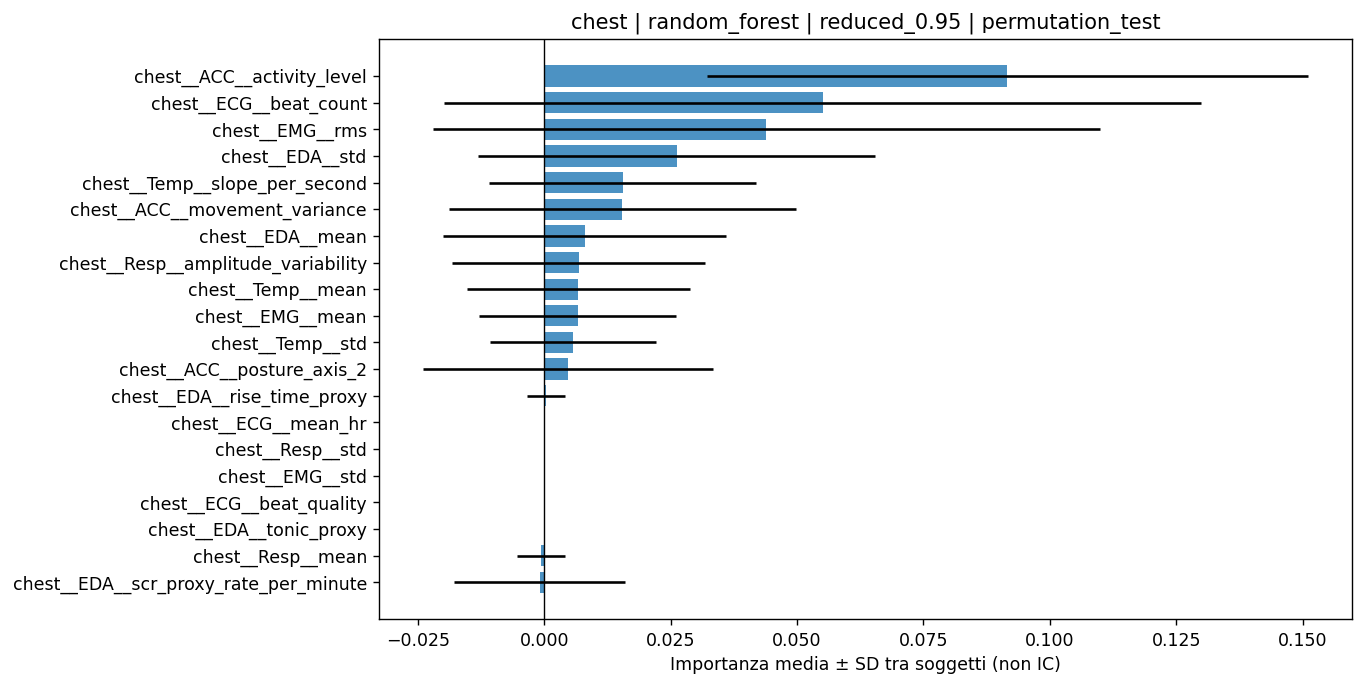

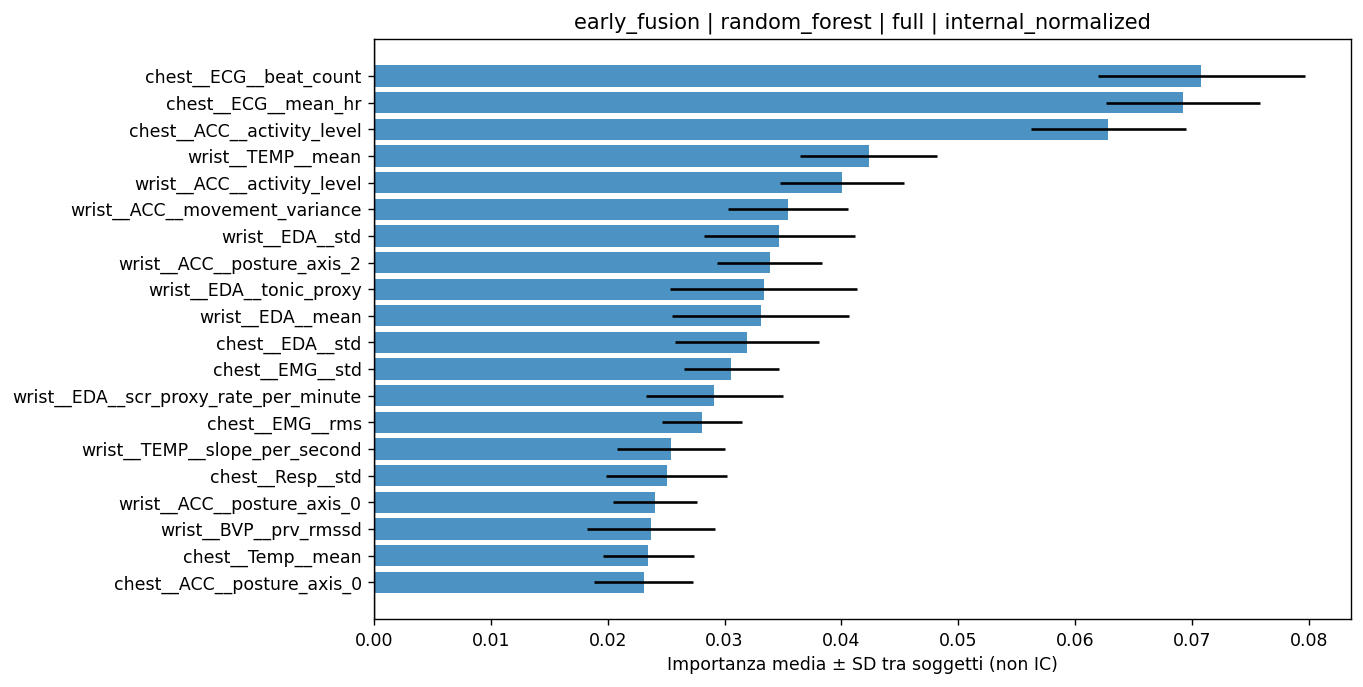

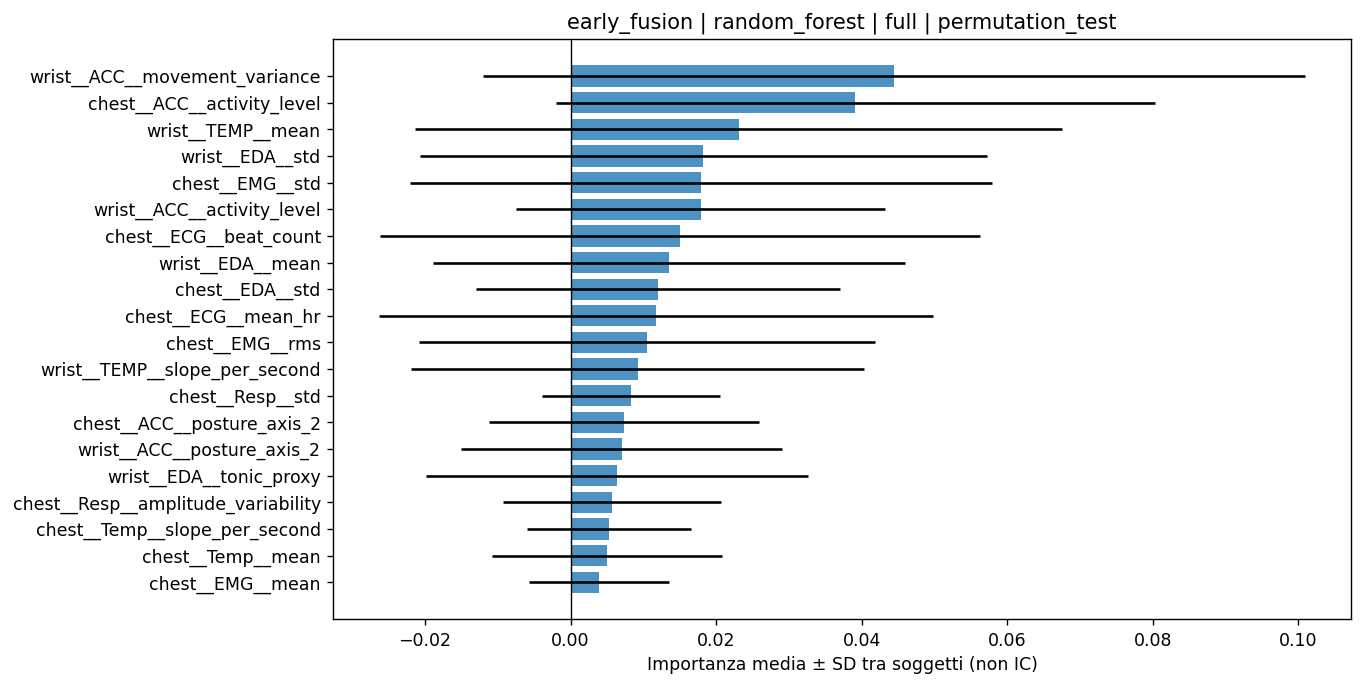

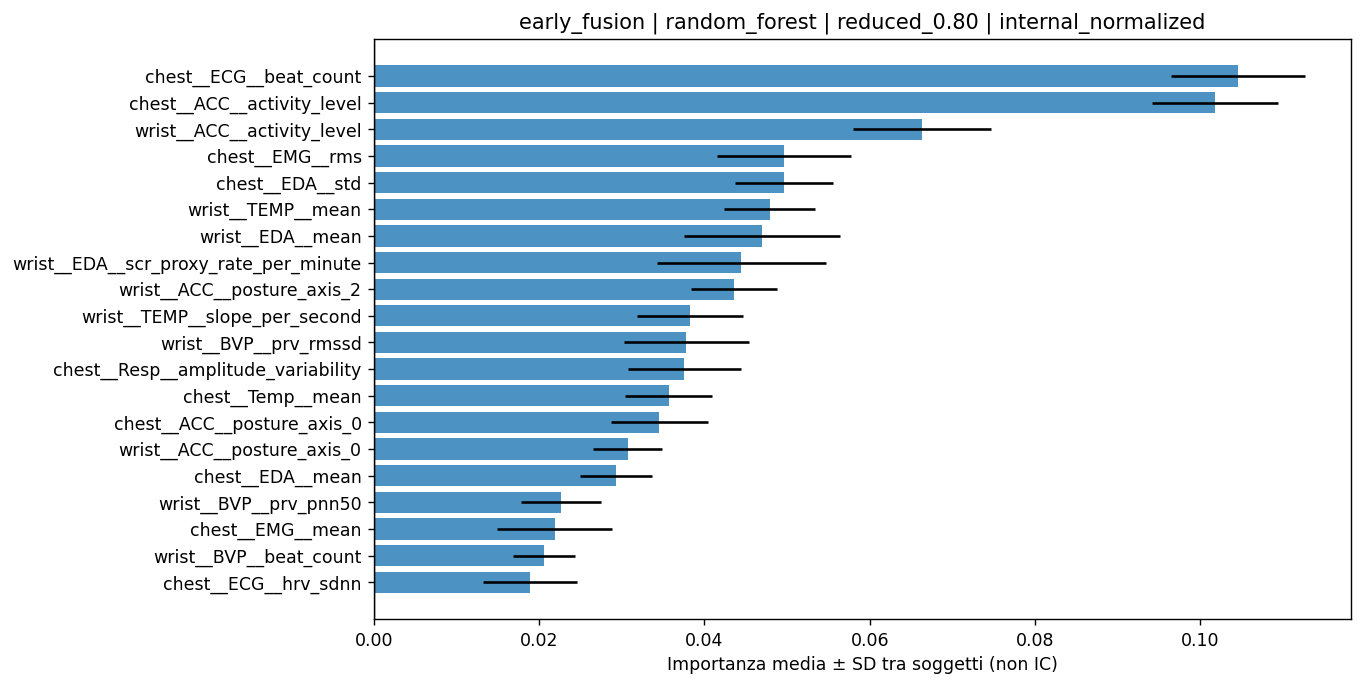

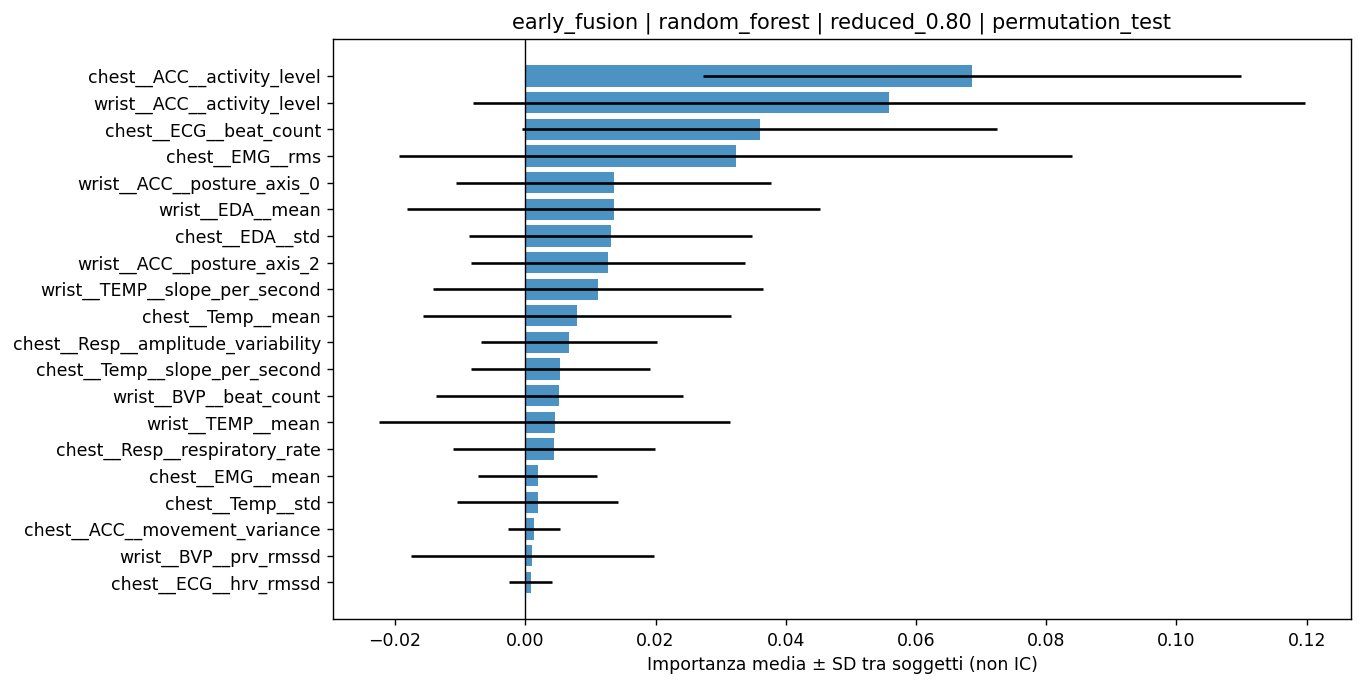

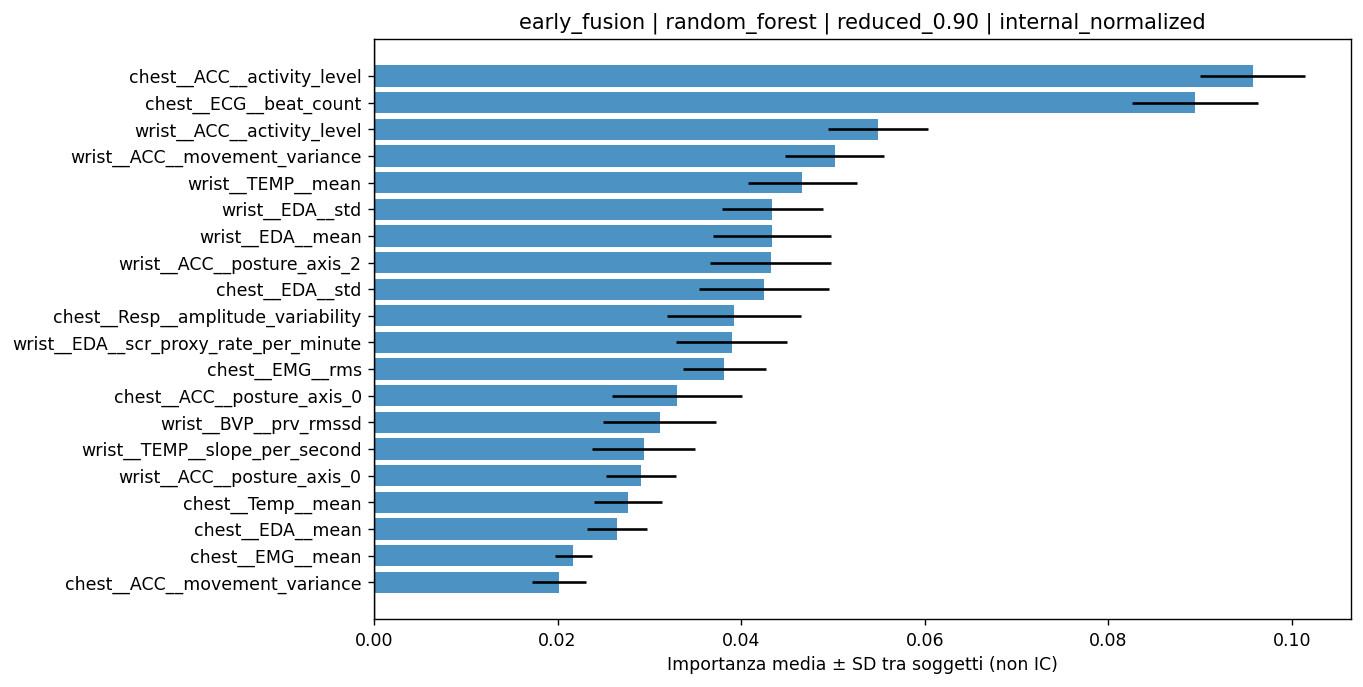

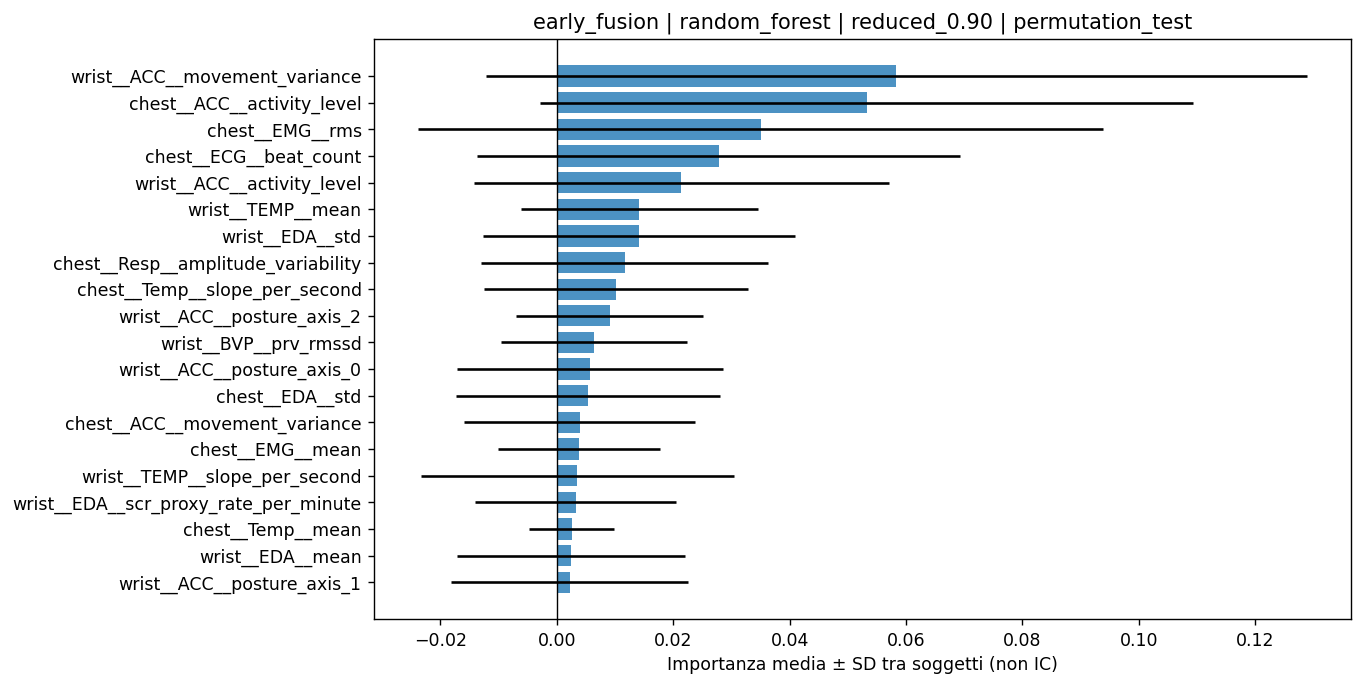

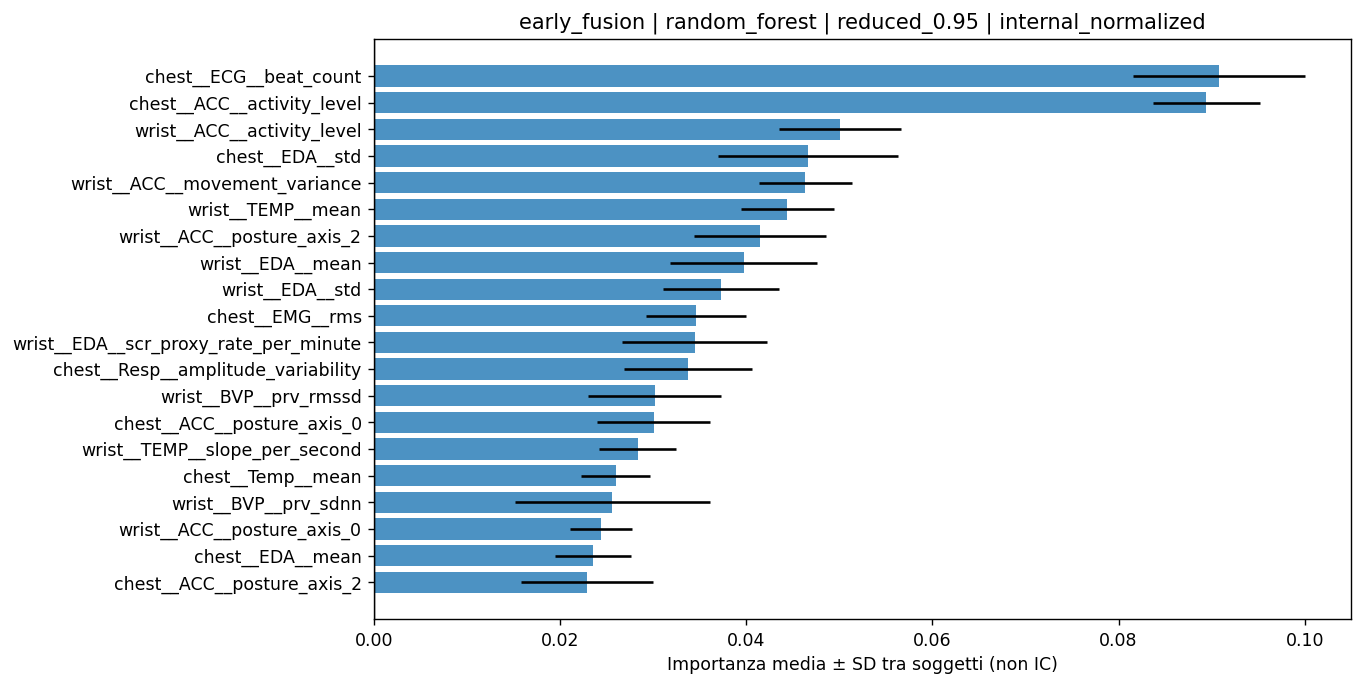

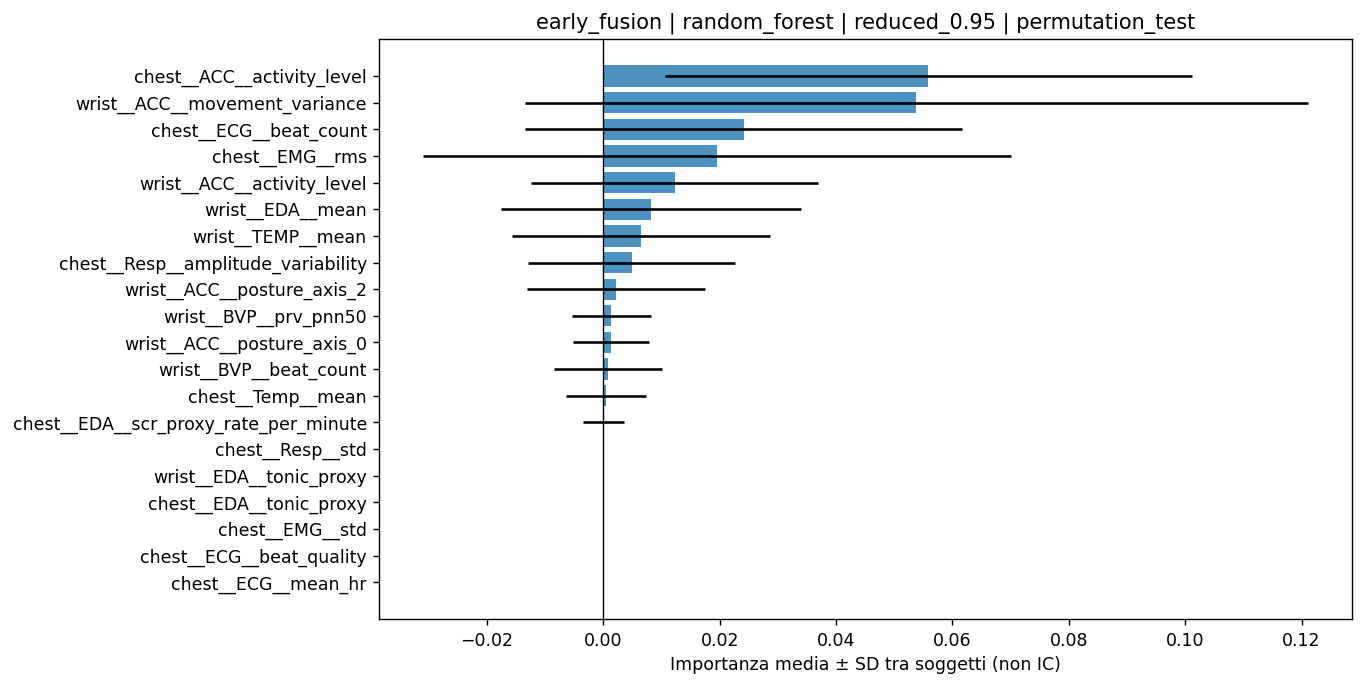

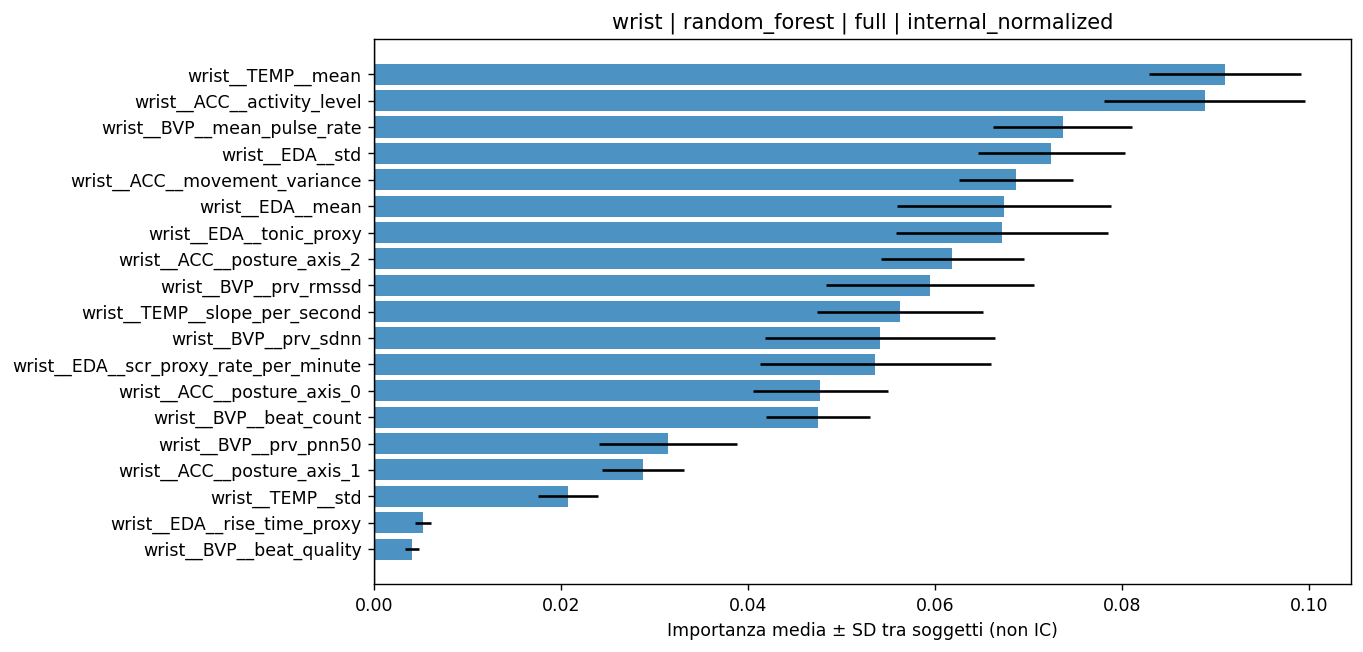

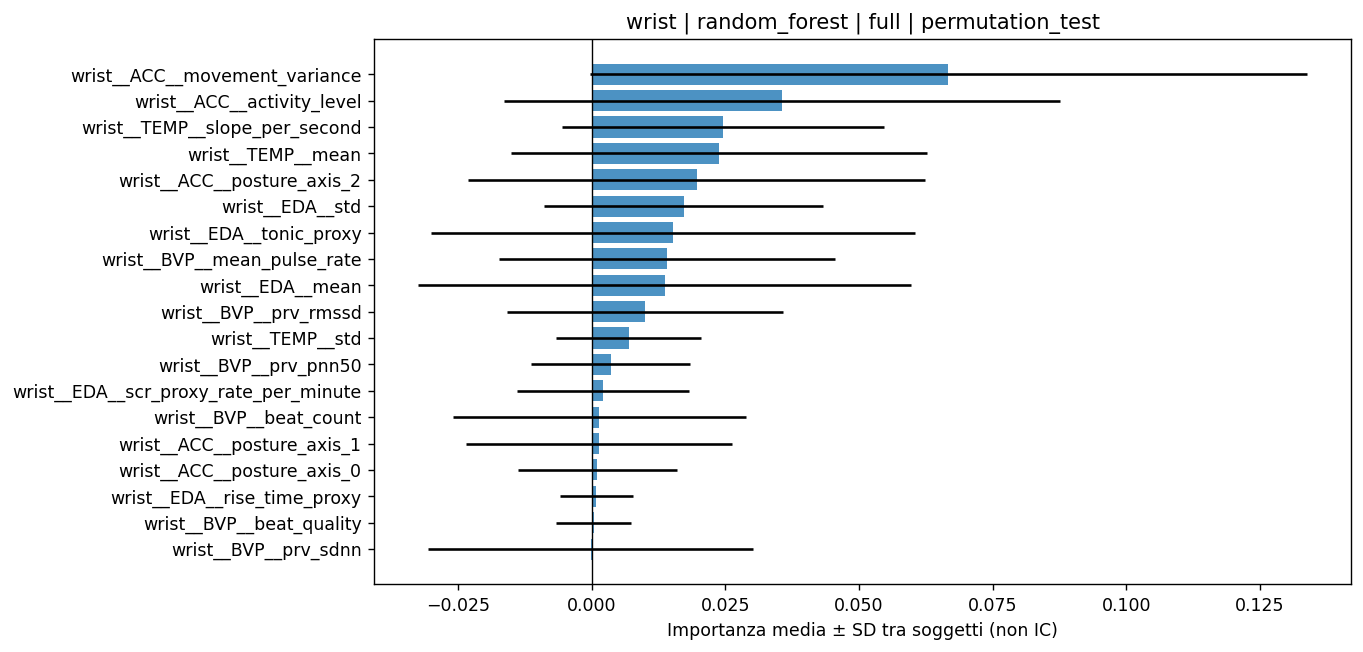

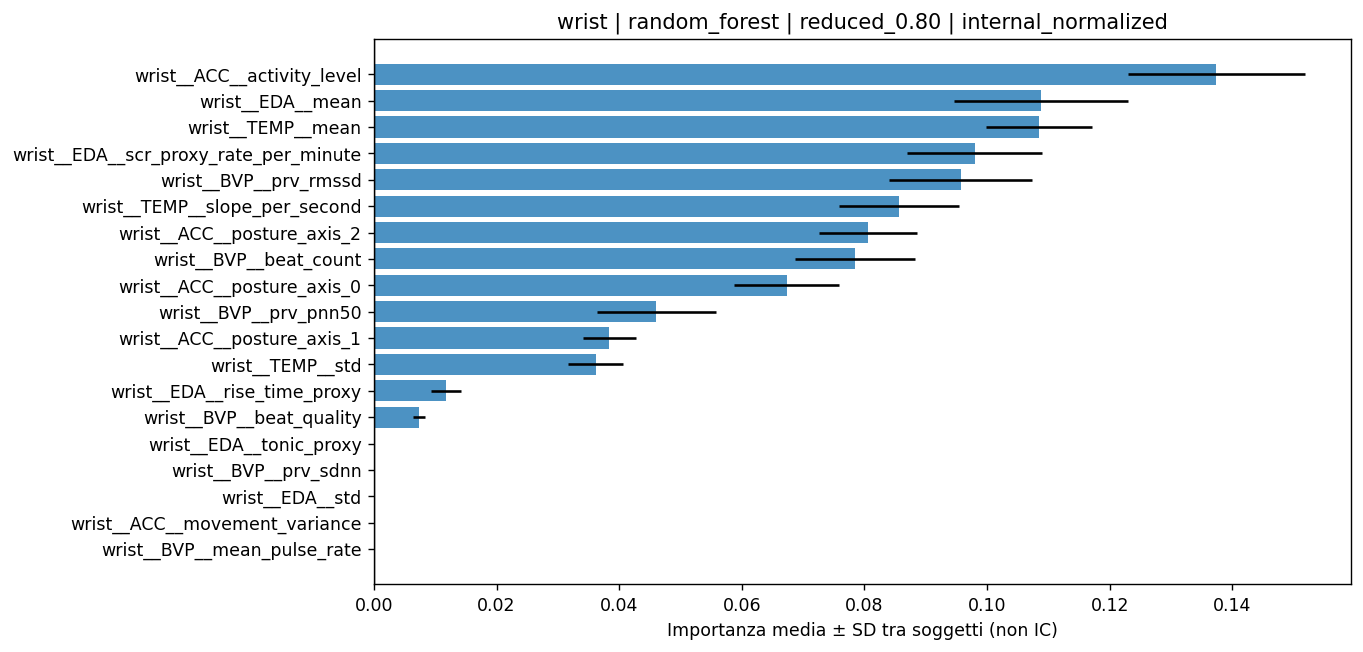

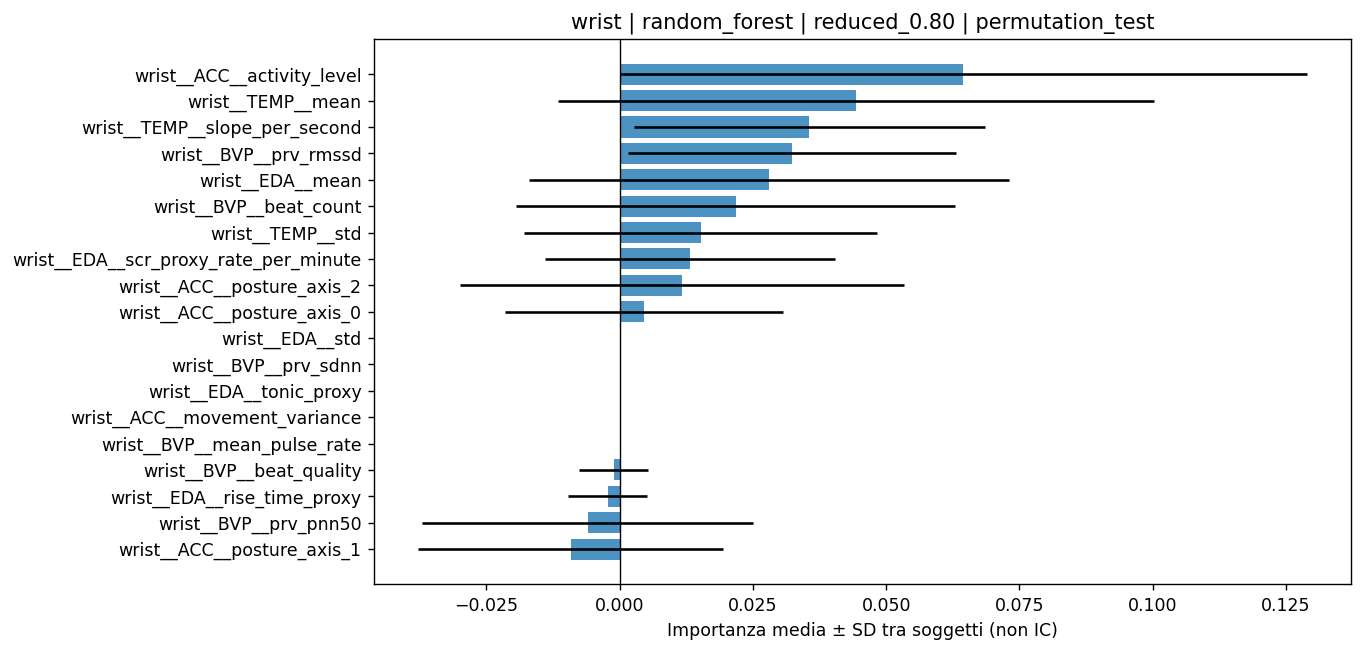

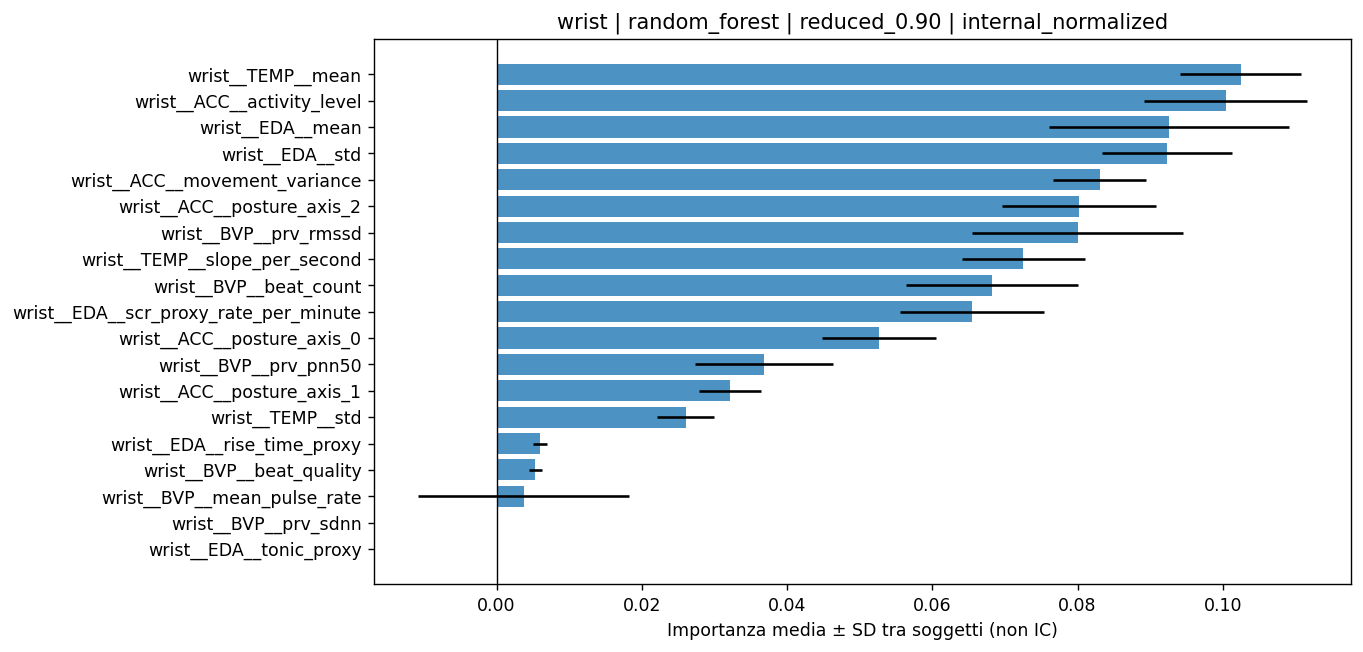

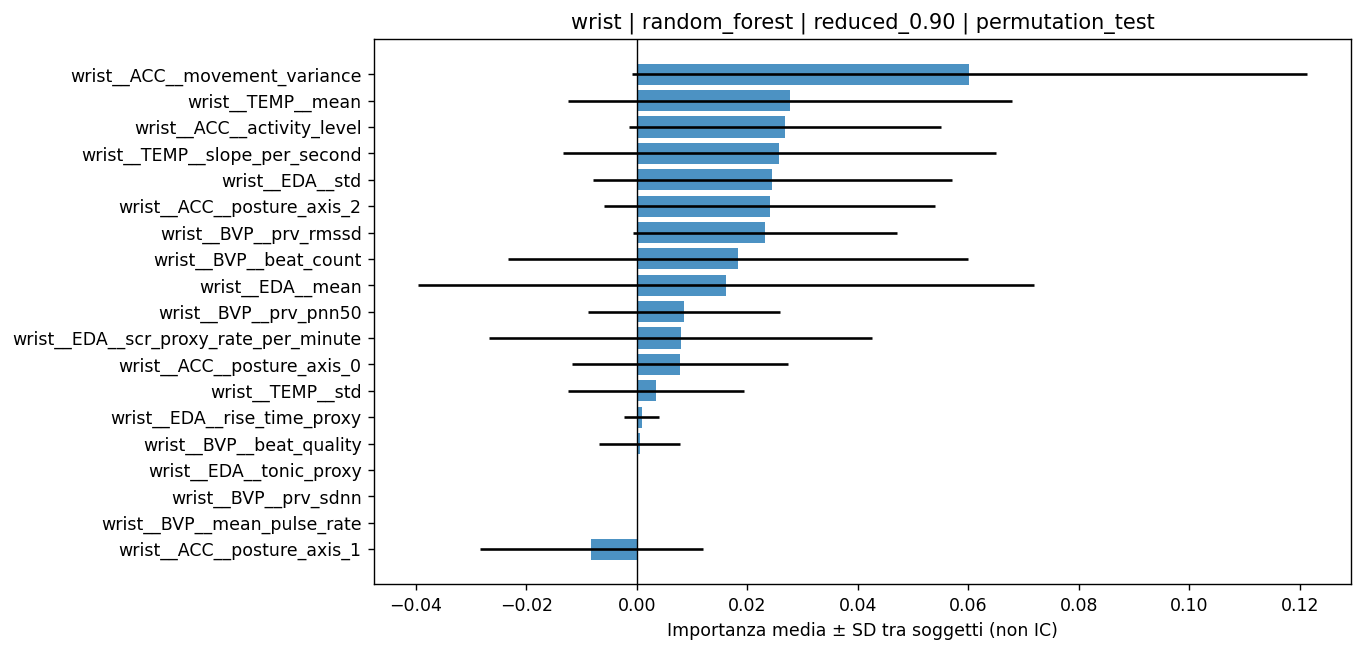

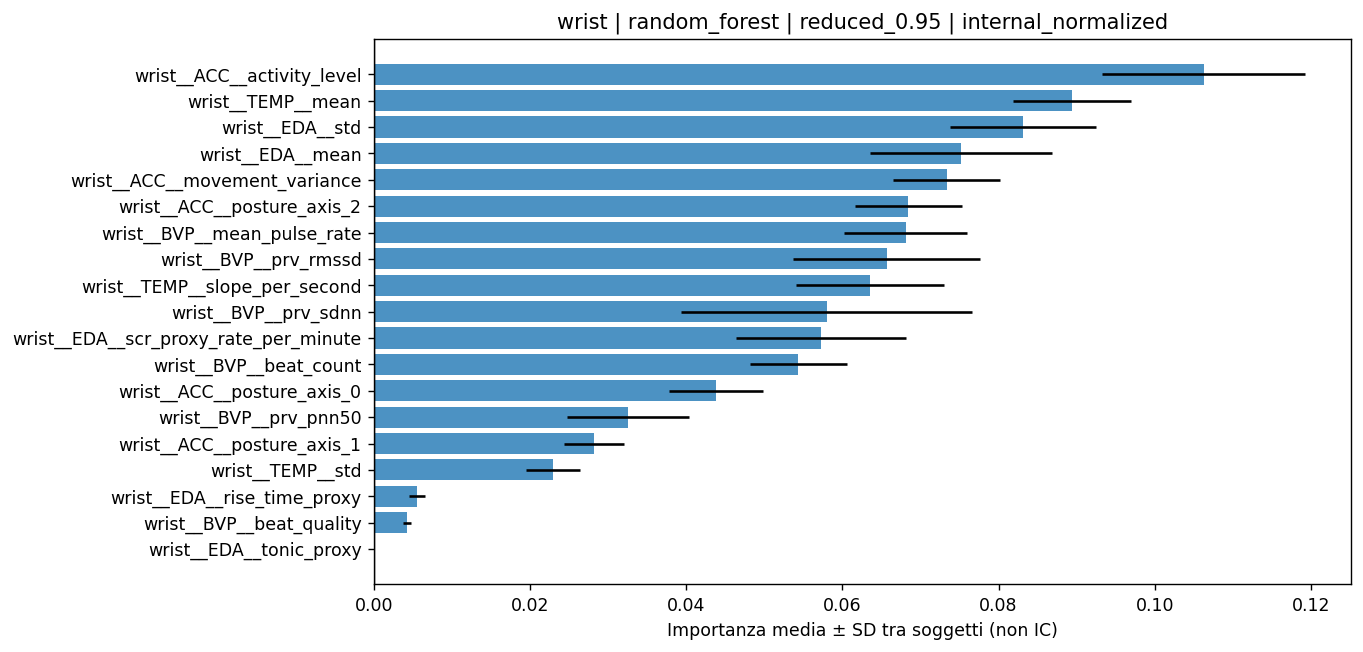

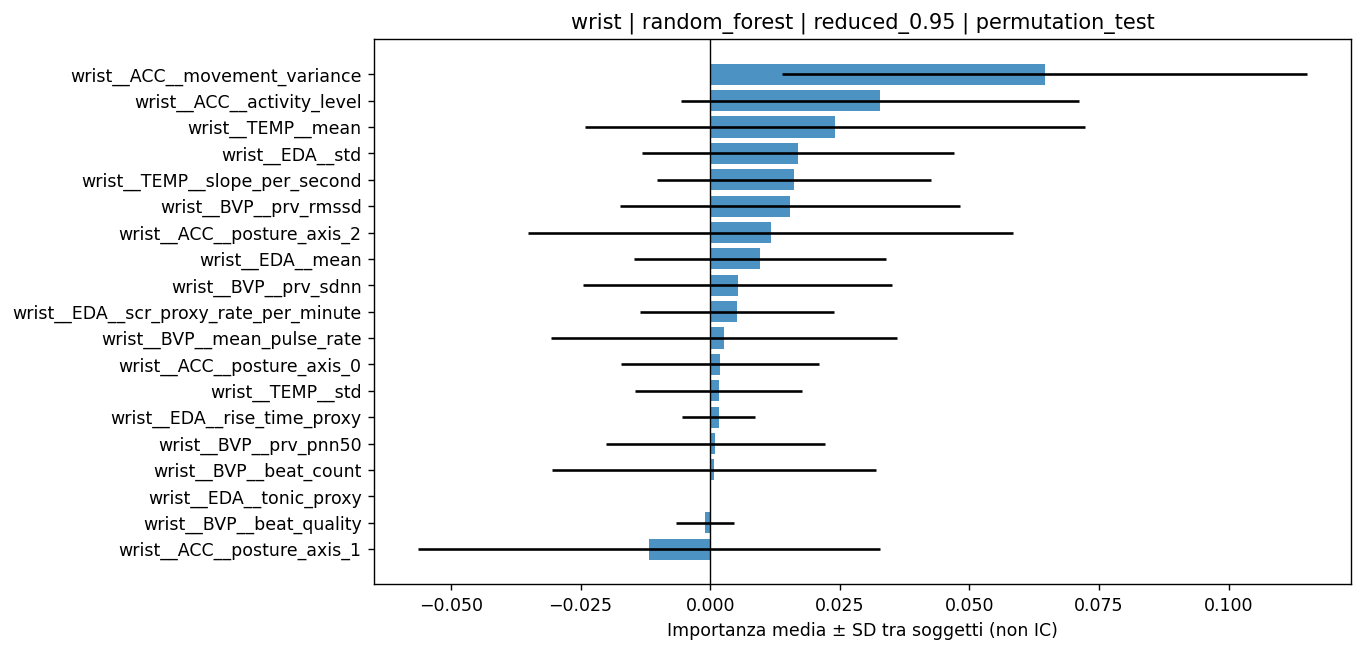

,feature,mean,std,selection_frequency,site,model,variant,kind
52,chest__ACC__activity_level,0.162550,0.017077,1.0,chest,random_forest,reduced_0.80,internal_normalized
104,chest__ACC__activity_level,0.150899,0.013381,1.0,chest,random_forest,reduced_0.90,internal_normalized
57,chest__ECG__beat_count,0.143841,0.012722,1.0,chest,random_forest,reduced_0.80,internal_normalized
156,chest__ACC__activity_level,0.142525,0.007121,1.0,chest,random_forest,reduced_0.95,internal_normalized
161,chest__ECG__beat_count,0.140849,0.008208,1.0,chest,random_forest,reduced_0.95,internal_normalized
109,chest__ECG__beat_count,0.139984,0.011120,1.0,chest,random_forest,reduced_0.90,internal_normalized
606,wrist__ACC__activity_level,0.137401,0.014420,1.0,wrist,random_forest,reduced_0.80,internal_normalized
10,chest__ECG__mean_hr,0.121113,0.011579,1.0,chest,random_forest,full,internal_normalized
617,wrist__EDA__mean,0.108798,0.014212,1.0,wrist,random_forest,reduced_0.80,internal_normalized
622,wrist__TEMP__mean,0.108448,0.008630,1.0,wrist,random_forest,reduced_0.80,internal_normalized


In [5]:
# Read the latest saved tables so an interrupted session cannot leave stale variables.
for variable, filename in [
    ('fold_metrics','fold_metrics.csv'),
    ('selection','feature_selection.csv'),
    ('importances','feature_importances.csv'),
]:
    file=OUT/filename
    if file.is_file() and file.stat().st_size > 2:
        try:
            globals()[variable]=pd.read_csv(file)
        except pd.errors.EmptyDataError:
            pass

if 'importances' not in globals():
    raise RuntimeError('Run the training cell first: no importance table is available.')
if importances.empty:
    completed_models=(sorted(fold_metrics.model.unique())
                      if 'fold_metrics' in globals() and not fold_metrics.empty else [])
    raise RuntimeError(
        f'No tree importances collected. Completed models: {completed_models}. '
        'If only logistic_regression is present, complete the random_forest folds. '
        'If random_forest is present, rerun the corrected training cell; '
        'importance values cannot be reconstructed from metrics alone.'
    )
expected_subjects={site:frames[site].subject_id.nunique() for site in SITES}
display(fold_metrics.groupby(['site','model','variant']).subject_id.nunique().rename('completed_subjects'))
for (site,model,variant),g in fold_metrics.groupby(['site','model','variant']):
    if g.subject_id.nunique()!=expected_subjects[site]:
        warnings.warn(f'Incomplete LOSO: {site}, {model}, {variant}. Plots are preliminary.')
tree_runs=fold_metrics[fold_metrics.model.isin(['random_forest','xgboost','lightgbm'])]
for row in tree_runs[['site','model','variant','subject_id']].drop_duplicates().itertuples(index=False):
    match=importances[(importances.site==row.site)&(importances.model==row.model)&
        (importances.variant==row.variant)&(importances.subject_id==row.subject_id)]
    if set(match.kind) != {'internal_normalized','permutation_test'}:
        raise RuntimeError(f'Incomplete tree importances for {tuple(row)}. Rerun the training cell.')
selection['selected']=selection.selected.astype(str).str.lower().eq('true')
if not importances.empty:
    completed=[]
    for (site,model,variant),group in fold_metrics.groupby(['site','model','variant']):
        part=importances[(importances.site==site)&(importances.model==model)&(importances.variant==variant)]
        if part.empty:continue
        universe=selection[(selection.site==site)&(selection.model==model)&(selection.variant==variant)]
        for kind in part.kind.unique():
            joined=universe.merge(part[part.kind.eq(kind)][['subject_id','feature','importance']],
                on=['subject_id','feature'],how='left',validate='one_to_one')
            # Missing internal entries correspond to features absent after preprocessing.
            if kind=='internal_normalized':joined['importance']=joined.importance.fillna(0.)
            if joined.importance.isna().any():raise ValueError('Importanze di test mancanti.')
            summary=joined.groupby('feature').agg(mean=('importance','mean'),
                std=('importance','std'),selection_frequency=('selected','mean')).reset_index()
            summary['site']=site;summary['model']=model;summary['variant']=variant;summary['kind']=kind
            completed.append(summary)
            top=summary.nlargest(TOP_N,'mean').sort_values('mean')
            fig,ax=plt.subplots(figsize=(11,max(5,len(top)*.28)))
            ax.barh(top.feature,top['mean'],xerr=top['std'].fillna(0),alpha=.8)
            ax.axvline(0,color='black',linewidth=.8)
            ax.set(title=f'{site} | {model} | {variant} | {kind}',
                xlabel='Importanza media ± SD tra soggetti (non IC)')
            fig.tight_layout();show(fig,f'importance_{site}_{model}_{variant}_{kind}.png')
    importance_summary=pd.concat(completed,ignore_index=True)
    importance_summary.to_csv(OUT/'importance_subject_summary.csv',index=False)
    display(importance_summary.sort_values('mean',ascending=False).head(40))


In [6]:
manifest={'analysis_role':'exploratory','thresholds':CORRELATION_THRESHOLDS,
    'correlation_method':CORRELATION_METHOD,'selection_rule':'alphabetical greedy; training only',
    'sites':SITES,'models':MODELS,'nested_subject_tuning':True,
    'permutation_repeats':N_PERMUTATION_REPEATS,'seed':SEED,
    'config_sha256':fingerprint(c),'importance_use':'descriptive only; no test-driven selection'}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Results saved successfully.')


Results saved successfully.
